# Grad-CAM from scratch: where does the classifier look?

A 97 %-accurate classifier can still be right for the wrong reasons: the background, a watermark, the typical
camera angle of the dataset. Before a perception model drives a robot we want evidence that it looks at the **object**.
**Grad-CAM** (Selvaraju et al., 2017) is the standard first tool for this. It produces a class-specific heat map from one
forward and one backward pass.

This notebook implements Grad-CAM **from scratch with PyTorch hooks**. We deliberately do not use the `grad-cam` package,
because it pulls in `opencv-python-headless`, which would clash with the repository's OpenCV 5 build. We apply it to the
ResNet-18 models trained in notebook 01 and then ask whether the explanations can be trusted.

**What you'll learn**
- the Grad-CAM equations and why they use the *last convolutional stage*;
- PyTorch **forward hooks** and **tensor gradient hooks** to capture activations and gradients;
- how to check that a saliency method is **class-discriminative**, using a two-object composite;
- the **model-randomisation sanity check** (Adebayo et al., 2018): an explanation that does not change when the weights are
  randomised explains nothing;
- the quantitative **deletion / insertion** faithfulness metrics (Petsiuk et al., 2018), compared against honest baselines.

**Prerequisites:** notebook 01 and its training run, which provides the checkpoints in `runs/02_representation_learning/transfer/`.
Runtime is about 1 minute on an RTX 5060 Laptop GPU.

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import spearmanr

from cvlab import viz
from cvlab.device import peak_vram_mb, reset_peak_vram, setup
from cvlab.io import project_dir, repo_root, runs_dir

PROJECT = "02_representation_learning"
PROJ = project_dir(PROJECT)
sys.path.insert(0, str(PROJ / "scripts"))
import replearn as rl

device = setup(seed=0)
viz.set_style()
CKPTS = runs_dir(PROJECT, "transfer")
print("checkpoints:", Path(CKPTS).relative_to(repo_root()).as_posix())

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
checkpoints: runs/02_representation_learning/transfer


## 1. The Grad-CAM equations

Take a convolutional layer with $K$ feature maps $A^k \in \mathbb{R}^{h \times w}$ and the **pre-softmax score**
$y^c$ of class $c$. Grad-CAM asks how much each feature map matters for class $c$ and where that feature map is active.

1. **Channel importance**: global-average-pool the gradient,
   $$\alpha_k^c = \frac{1}{hw}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}.$$
2. **Weighted combination, positive part only**:
   $$L^c_\text{Grad-CAM} = \mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big) \in \mathbb{R}^{h \times w}.$$
   The ReLU keeps regions that *increase* the class score. Negative evidence usually belongs to other classes.
3. Upsample $L^c$ bilinearly to the input size and scale it to $[0, 1]$ for display.

**Which layer?** Deep layers are semantic but coarse, and shallow layers are sharp but not class-specific. The usual choice is the
output of the last convolutional stage. For ResNet-18 that is `layer4`, which has a stride of 32. At our 160 px input it gives
only a **5x5 grid**, so the maps below are blobby by construction. Exercise 1 explores this trade-off.

**Hooks.** `module.register_forward_hook(fn)` calls `fn(module, inputs, output)` after every forward pass of `module`. In it
we store $A$ and register a *tensor hook* (`output.register_hook`), which autograd calls with $\partial y^c / \partial A$
during `backward()`. Hooks avoid modifying the model's code, so the same class works for any CNN.

In [2]:
# --- Grad-CAM from scratch: a forward hook stores A, a tensor hook stores dy_c/dA ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.acts = output  # A: (B, K, h, w)
        output.register_hook(lambda grad: setattr(self, "grads", grad))  # called in backward()

    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.detach().clone().requires_grad_(True)  # keeps a graph even if the trunk is frozen
        logits = self.model(x)  # (B, C) pre-softmax scores y
        idx = logits.argmax(1) if class_idx is None else torch.as_tensor(class_idx, device=x.device).expand(len(x))
        self.model.zero_grad(set_to_none=True)
        logits.gather(1, idx[:, None]).sum().backward()  # d(sum_b y^c_b)/dA = per-image gradients
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)  # (B, K, 1, 1) channel importances
        cam = F.relu((alpha * self.acts.detach()).sum(1, keepdim=True))  # (B, 1, h, w)
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = cam / cam.flatten(1).amax(1).clamp_min(1e-12)[:, None, None]  # per-image max = 1
        return cam, logits.detach()

    def remove(self):
        self.handle.remove()

## 2. Load the models from notebook 01

We explain the **fine-tuned** ResNet-18 (97.43 % val accuracy). For comparison we also load the **linear-probe** ResNet-18,
whose trunk still holds the original ImageNet weights. Grad-CAM needs gradients, so these models run in fp32 without
autocast. At 160 px that is cheap. We also check our notebook implementation against the unit-tested reference in
`replearn.py` on a batch of validation images.

In [3]:
# --- Load checkpoints, build the val set and cross-check the two Grad-CAM implementations ---
def load(name, mode):
    m = rl.build_model(name, mode, pretrained=False)
    m.load_state_dict(torch.load(CKPTS / f"{name}__{mode}.pt", map_location="cpu", weights_only=True))
    return m.to(device).eval()


ft = load("resnet18.a1_in1k", "finetune")
lp = load("resnet18.a1_in1k", "linear_probe")
val_ds = rl.make_dataset("val", rl.build_transform(train=False, size=160))
y_all = np.asarray(val_ds.targets)

xb = torch.stack([val_ds[i][0] for i in range(0, 3925, 400)]).to(device)  # 10 images, (10, 3, 160, 160)
cam_nb = GradCAM(ft, ft.layer4)
cam_ref = rl.GradCAM(ft, ft.layer4)
h_nb, logits = cam_nb(xb)
h_ref, _ = cam_ref(xb)
cam_nb.remove()
cam_ref.remove()
print("layer4 activation shape:", tuple(cam_nb.acts.shape), "| CAM shape:", tuple(h_nb.shape))
print("max |notebook - reference| =", float((h_nb - h_ref).abs().max()))

layer4 activation shape: (10, 512, 5, 5) | CAM shape: (10, 160, 160)
max |notebook - reference| = 0.0


## 3. A Grad-CAM gallery

One random validation image per class. Each map explains the model's **top-1 prediction**, and the title shows the
true label, the prediction and its softmax probability.

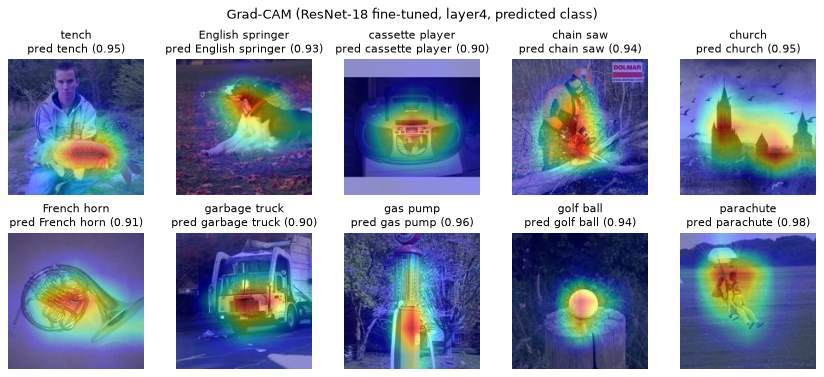

In [4]:
# --- Grad-CAM of the predicted class for one validation image per class ---
def overlay(img_u8, cam, alpha=0.45):
    # Blend a [0, 1] heat map (jet colormap) onto an RGB uint8 image -> float RGB in [0, 1].
    heat = plt.get_cmap("jet")(np.asarray(cam))[..., :3]
    return ((1 - alpha) * img_u8 / 255.0 + alpha * heat).clip(0, 1)


rng = np.random.default_rng(1)
gal_idx = [int(rng.choice(np.flatnonzero(y_all == c))) for c in range(10)]
xg = torch.stack([val_ds[i][0] for i in gal_idx]).to(device)
cam = GradCAM(ft, ft.layer4)
hg, lg = cam(xg)
cam.remove()
pg = lg.softmax(1)
imgs = rl.denormalize(xg)
titles = [f"{rl.CLASS_NAMES[y_all[i]]}\npred {rl.CLASS_NAMES[int(pg[j].argmax())]} ({float(pg[j].max()):.2f})"
          for j, i in enumerate(gal_idx)]
fig = viz.show_images([overlay(imgs[j], hg[j].cpu()) for j in range(10)], titles=titles, ncols=5, size=2.1,
                      suptitle="Grad-CAM (ResNet-18 fine-tuned, layer4, predicted class)")
fig.set_dpi(80)  # photo grids: lower display dpi keeps the notebook small
viz.savefig(fig, PROJECT, "gradcam_gallery")
plt.show()

## 4. Is it class-discriminative? A two-object composite

A good explanation should change with the class we ask about. We paste two validation images side by side into one
160x320 input. ResNet is fully convolutional up to the global pooling, so any input size works. Then we compute Grad-CAM for
*each* of the two classes. If the method is class-discriminative, the two maps light up different halves.

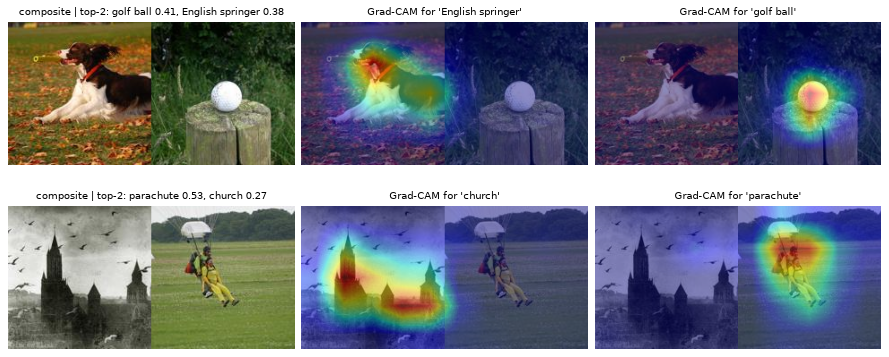

In [5]:
# --- Composite images: Grad-CAM for the left-object class vs. the right-object class ---
pairs = [(1, 8), (4, 9)]  # (English springer | golf ball), (church | parachute)
fig, axes = plt.subplots(len(pairs), 3, figsize=(11, 2.3 * len(pairs)), dpi=80)
cam = GradCAM(ft, ft.layer4)
for r, (ca, cb) in enumerate(pairs):
    ia, ib = gal_idx[ca], gal_idx[cb]
    comp = torch.cat([val_ds[ia][0], val_ds[ib][0]], dim=2)[None].to(device)  # (1, 3, 160, 320)
    img = rl.denormalize(comp[0])
    probs = ft(comp).softmax(1)[0]
    axes[r, 0].imshow(img)
    top2 = probs.topk(2)
    axes[r, 0].set_title("composite | top-2: " + ", ".join(
        f"{rl.CLASS_NAMES[int(i)]} {float(p):.2f}" for p, i in zip(top2.values, top2.indices)), fontsize=9)
    for col, c in [(1, ca), (2, cb)]:
        h, _ = cam(comp, class_idx=c)
        axes[r, col].imshow(overlay(img, h[0].cpu()))
        axes[r, col].set_title(f"Grad-CAM for '{rl.CLASS_NAMES[c]}'", fontsize=9)
cam.remove()
for ax in axes.flat:
    ax.axis("off")
viz.savefig(fig, PROJECT, "gradcam_class_discriminative")
plt.show()

## 5. Sanity checks: fine-tuned vs. linear probe vs. randomised weights

Adebayo et al. (2018) showed that some popular saliency methods produce almost the same maps for a **randomly initialised**
network. Those methods behave like edge detectors and do not explain the model. The **model-randomisation test**:

- compute maps for the trained model;
- re-initialise the weights, either only `layer4` and the head (top-down cascading randomisation) or the whole network, and recompute;
- measure the **Spearman rank correlation** between the trained and randomised maps over many images. Low correlation means the
  method depends on what the model learned, which is what we want.

We also compare the fine-tuned model with the **linear probe**. Its trunk is the untouched ImageNet ResNet-18, so the
correlation shows how much fine-tuning changed *where* the network looks. We use 300 validation images, 30 per class, and every map explains
the fine-tuned model's predicted class.

In [6]:
# --- Spearman correlation between Grad-CAM maps of the trained and modified models ---
import copy

rng = np.random.default_rng(0)
eval_idx = np.concatenate([rng.choice(np.flatnonzero(y_all == c), 30, replace=False) for c in range(10)])
X_eval = torch.stack([val_ds[int(i)][0] for i in eval_idx])  # (300, 3, 160, 160) on CPU


def reinit(module):
    # Re-initialise every sub-module that knows how (Conv2d, BatchNorm2d, Linear).
    for m in module.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()


torch.manual_seed(0)
top_random = copy.deepcopy(ft)
reinit(top_random.layer4)
reinit(top_random.fc)
full_random = rl.build_model("resnet18.a1_in1k", "finetune", pretrained=False).to(device).eval()
models = {"fine-tuned": ft, "linear probe": lp, "layer4+head randomised": top_random, "fully random": full_random}


def cams_for(model, X, classes, bs=100):
    gc = GradCAM(model, model.layer4)
    out = [gc(X[i:i + bs].to(device), class_idx=classes[i:i + bs])[0].cpu() for i in range(0, len(X), bs)]
    gc.remove()
    return torch.cat(out)


with torch.no_grad():
    pred_eval = torch.cat([ft(X_eval[i:i + 100].to(device)).argmax(1) for i in range(0, 300, 100)])
maps = {name: cams_for(m, X_eval, pred_eval) for name, m in models.items()}
sanity = {}
for name in ["linear probe", "layer4+head randomised", "fully random"]:
    rho = [spearmanr(maps["fine-tuned"][i].flatten(), maps[name][i].flatten())[0] for i in range(len(X_eval))]
    rho = np.nan_to_num(np.asarray(rho))  # an all-zero map has undefined rank correlation -> 0
    sanity[name] = {"median Spearman rho vs. fine-tuned": np.median(rho), "mean": rho.mean(), "std": rho.std()}
pd.DataFrame(sanity).T.style.format("{:.3f}")

,median Spearman rho vs. fine-tuned,mean,std
linear probe,0.926,0.885,0.119
layer4+head randomised,0.034,0.046,0.355
fully random,0.000,0.033,0.330


The same comparison visually, for five images (rows: models, columns: images):

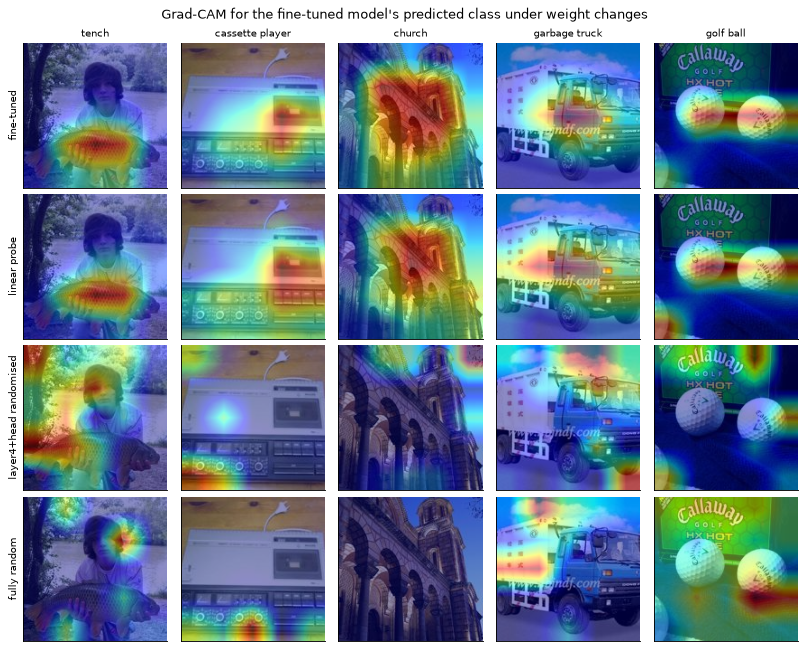

In [7]:
# --- Visual comparison of Grad-CAM maps across the four models ---
show = [0, 61, 122, 183, 244]
imgs = rl.denormalize(X_eval[show])
fig, axes = plt.subplots(len(models), len(show), figsize=(2.0 * len(show), 2.0 * len(models)), dpi=80)
for r, name in enumerate(models):
    for c, i in enumerate(show):
        axes[r, c].imshow(overlay(imgs[c], maps[name][i]))
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        axes[r, c].grid(False)
    axes[r, 0].set_ylabel(name, fontsize=9)
for c, i in enumerate(show):
    axes[0, c].set_title(rl.CLASS_NAMES[int(pred_eval[i])], fontsize=9)
fig.suptitle("Grad-CAM for the fine-tuned model's predicted class under weight changes")
viz.savefig(fig, PROJECT, "gradcam_sanity")
plt.show()

## 6. Faithfulness: deletion and insertion curves

A saliency map is **faithful** if the pixels it ranks highest really drive the prediction. Petsiuk et al. (2018) measure this by
removing pixels in order of saliency, replacing them with a heavily blurred copy of the image:

- **Deletion**: remove the top fraction $f$ of pixels and track $p(c \mid x_f)$. A faithful map makes the probability **drop fast**,
  so a *lower* area under the curve (AUC) is better.
- **Insertion**: start from the blurred image and paste back the top pixels. A faithful map makes the probability **rise fast**,
  so a *higher* AUC is better.

Here $c$ is the model's own prediction on the clean image, and $f$ runs over $0, 1/16, \dots, 1$. Two baselines keep us honest:

- a **random coarse map**: random 5x5 noise upsampled the same way, so it is as smooth as Grad-CAM but carries no information;
- a **centre prior**: a fixed Gaussian blob in the image centre. Photographers centre their subjects, so this baseline is hard to beat.

The same 300 images are used, and both ResNet-18 models are scored on their own predictions.

In [8]:
# --- Deletion / insertion curves for Grad-CAM and two baselines (300 val images) ---
H = W = 160
yy, xx = torch.meshgrid(torch.arange(H), torch.arange(W), indexing="ij")
centre = torch.exp(-(((yy - H / 2) ** 2 + (xx - W / 2) ** 2) / (2 * (0.25 * H) ** 2)))  # (H, W) Gaussian
torch.manual_seed(0)
coarse_random = F.interpolate(torch.rand(len(X_eval), 1, 5, 5), size=(H, W), mode="bilinear",
                              align_corners=False)[:, 0]


def curves(model, saliency, classes, bs=50):
    d, i = [], []
    for s in range(0, len(X_eval), bs):
        dd, ii = rl.deletion_insertion(model, X_eval[s:s + bs].to(device), saliency[s:s + bs].to(device),
                                       classes[s:s + bs], steps=16)
        d.append(dd)
        i.append(ii)
    return np.concatenate(d), np.concatenate(i)


with torch.no_grad():
    pred_lp = torch.cat([lp(X_eval[i:i + 100].to(device)).argmax(1) for i in range(0, 300, 100)])
lp_maps = cams_for(lp, X_eval, pred_lp)
faith = {
    "Grad-CAM (fine-tuned)": curves(ft, maps["fine-tuned"], pred_eval),
    "random coarse map (fine-tuned)": curves(ft, coarse_random, pred_eval),
    "centre prior (fine-tuned)": curves(ft, centre.expand(len(X_eval), H, W), pred_eval),
    "Grad-CAM (linear probe)": curves(lp, lp_maps, pred_lp),
}

# Cost of one Grad-CAM call (forward + backward) for a batch of 100 images, fp32.
gc = GradCAM(ft, ft.layer4)
xb = X_eval[:100].to(device)
gc(xb)  # warm-up
torch.cuda.synchronize()
reset_peak_vram()
t0 = time.perf_counter()
for _ in range(10):
    gc(xb)
torch.cuda.synchronize()
gradcam_ms = (time.perf_counter() - t0) / 10 / 100 * 1000
gradcam_vram = peak_vram_mb()
gc.remove()
print(f"Grad-CAM cost: {gradcam_ms:.3f} ms / image (batch 100, fp32), peak VRAM {gradcam_vram:.0f} MiB")

Grad-CAM cost: 1.114 ms / image (batch 100, fp32), peak VRAM 1990 MiB


## Results

### Deletion and insertion curves

Mean softmax probability of the explained class over 300 validation images. The shaded band is ±1 standard error of the mean.

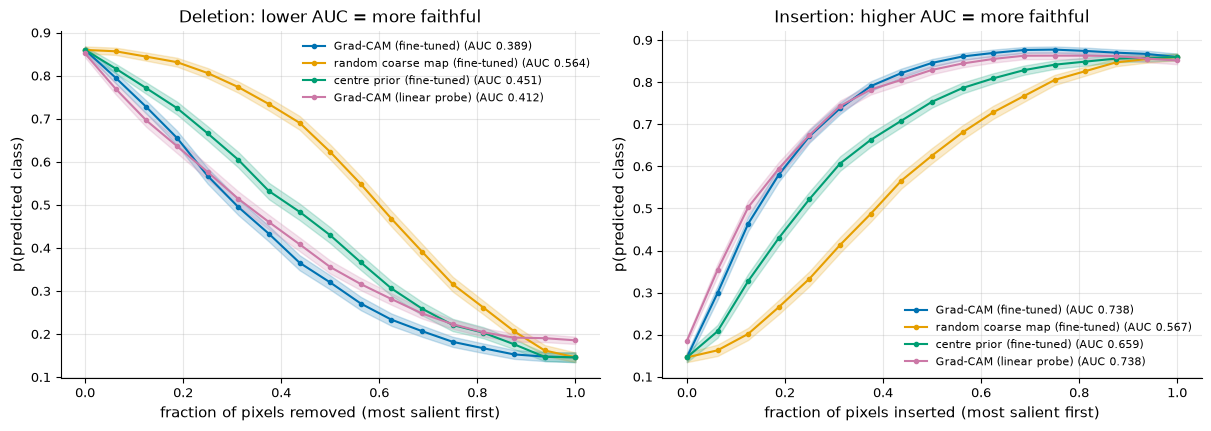

In [9]:
# --- Plot mean deletion / insertion curves with standard-error bands ---
frac = np.linspace(0, 1, 17)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (name, (dele, ins)) in enumerate(faith.items()):
    for ax, cur in [(axes[0], dele), (axes[1], ins)]:
        mu, se = cur.mean(0), cur.std(0) / np.sqrt(len(cur))
        ax.plot(frac, mu, "-o", ms=3, color=viz.color(i, unit=True), label=f"{name} (AUC {rl.auc(cur).mean():.3f})")
        ax.fill_between(frac, mu - se, mu + se, color=viz.color(i, unit=True), alpha=0.2)
axes[0].set(xlabel="fraction of pixels removed (most salient first)", ylabel="p(predicted class)",
            title="Deletion: lower AUC = more faithful")
axes[1].set(xlabel="fraction of pixels inserted (most salient first)", ylabel="p(predicted class)",
            title="Insertion: higher AUC = more faithful")
for ax in axes:
    ax.legend(fontsize=8)
viz.savefig(fig, PROJECT, "deletion_insertion")
plt.show()

### Explaining mistakes

For misclassified validation images, Grad-CAM can show what the model looked at to reach the **wrong** class and where the
**true** class evidence would be. We take the fine-tuned model's most confident errors on the full validation set.

99 errors on 3925 val images (fp32 accuracy 0.9748)


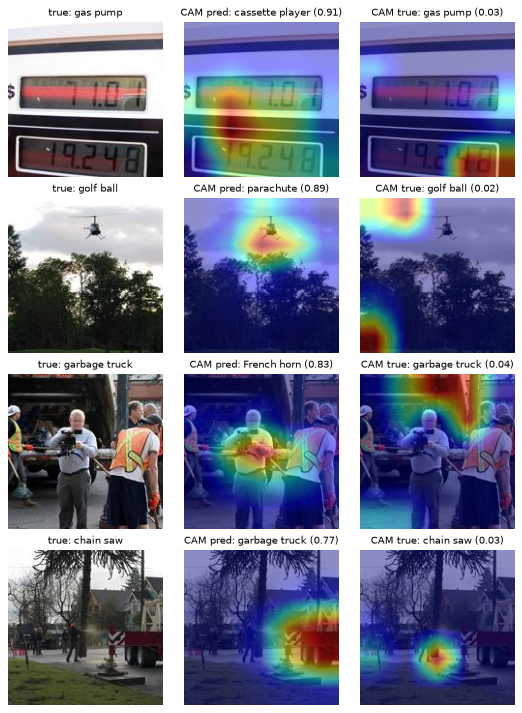

In [10]:
# --- Grad-CAM for predicted vs. true class on the most confident errors ---
val_dl = rl.make_loader(val_ds, batch_size=256, workers=8)
logits_all, y_chk = rl.predict(ft, val_dl, device, amp_dtype=None)
p_all = torch.from_numpy(logits_all).softmax(1).numpy()
pred_all = p_all.argmax(1)
wrong = np.flatnonzero(pred_all != y_all)
worst = wrong[np.argsort(-p_all[wrong, pred_all[wrong]])][:4]
xw = torch.stack([val_ds[int(i)][0] for i in worst]).to(device)
gc = GradCAM(ft, ft.layer4)
h_pred, _ = gc(xw)
h_true, _ = gc(xw, class_idx=torch.as_tensor(y_all[worst], device=device))
gc.remove()
imgs = rl.denormalize(xw)
fig, axes = plt.subplots(len(worst), 3, figsize=(6.6, 2.2 * len(worst)), dpi=80)
for r, i in enumerate(worst):
    axes[r, 0].imshow(imgs[r])
    axes[r, 0].set_title(f"true: {rl.CLASS_NAMES[y_all[i]]}", fontsize=9)
    axes[r, 1].imshow(overlay(imgs[r], h_pred[r].cpu()))
    axes[r, 1].set_title(f"CAM pred: {rl.CLASS_NAMES[pred_all[i]]} ({p_all[i, pred_all[i]]:.2f})", fontsize=9)
    axes[r, 2].imshow(overlay(imgs[r], h_true[r].cpu()))
    axes[r, 2].set_title(f"CAM true: {rl.CLASS_NAMES[y_all[i]]} ({p_all[i, y_all[i]]:.2f})", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
print(f"{len(wrong)} errors on {len(y_all)} val images (fp32 accuracy {(pred_all == y_all).mean():.4f})")
viz.savefig(fig, PROJECT, "gradcam_failures")
plt.show()

### Summary table

Faithfulness AUCs (mean ± standard deviation over 300 images) and the cost of Grad-CAM, measured on an RTX 5060 Laptop GPU (fp32, 160 px).

In [11]:
# --- Summary DataFrame: faithfulness metrics + Grad-CAM cost ---
rows = []
for name, (dele, ins) in faith.items():
    rows.append({"saliency (model)": name,
                 "deletion AUC (lower=better)": f"{rl.auc(dele).mean():.3f} ± {rl.auc(dele).std():.3f}",
                 "insertion AUC (higher=better)": f"{rl.auc(ins).mean():.3f} ± {rl.auc(ins).std():.3f}",
                 "Grad-CAM ms / image": f"{gradcam_ms:.3f}" if name == "Grad-CAM (fine-tuned)" else "-",
                 "Grad-CAM peak VRAM [MiB] (batch 100)": f"{gradcam_vram:.0f}" if name == "Grad-CAM (fine-tuned)" else "-"})
summary = pd.DataFrame(rows).set_index("saliency (model)")
summary

,deletion AUC (lower=better),insertion AUC (higher=better),Grad-CAM ms / image,Grad-CAM peak VRAM [MiB] (batch 100)
saliency (model),,,,
Grad-CAM (fine-tuned),0.389 ± 0.198,0.738 ± 0.149,1.114,1990
random coarse map (fine-tuned),0.564 ± 0.184,0.567 ± 0.194,-,-
centre prior (fine-tuned),0.451 ± 0.208,0.659 ± 0.185,-,-
Grad-CAM (linear probe),0.412 ± 0.191,0.738 ± 0.154,-,-


### Takeaways

- **The hook implementation is correct and cheap.** It matches the unit-tested reference exactly (maximum difference 0.0) and costs
  1.114 ms per image (batch 100, fp32, 1990 MiB peak VRAM), cheap enough to log explanations of a robot's decisions online.
- **Grad-CAM is class-discriminative.** On both two-object composites, the map for each class covers the half that contains that
  object, including the class that is *not* the model's top-1 prediction.
- **It passes the model-randomisation sanity check.** Re-initialising only `layer4` and the head drops the median Spearman correlation
  with the trained model's maps to 0.034, and a fully random network gives 0.000. The maps therefore depend on the learned weights.
  The linear probe, whose trunk is the untouched ImageNet ResNet-18, gives very similar maps (median ρ = 0.926): fine-tuning on
  Imagenette barely changed *where* the network looks, which fits the small accuracy gap between the two models.
- **Faithful, but only modestly better than a trivial prior.** Grad-CAM has a deletion AUC of 0.389 and an insertion AUC of 0.738. That
  is better than a random coarse map (0.564 / 0.567) and a centre-prior blob (0.451 / 0.659). Still, the centre prior alone closes
  54-65 % of the gap between the random map and Grad-CAM, because Imagenette photos are object-centred. The per-image standard
  deviations (0.15-0.21) are large, so judge single explanations with care.
- **Grad-CAM is a debugging tool for the data, too.** The most confident errors are mostly ambiguous or questionable images rather
  than plain model failures: a "golf ball" photo whose predicted-class map (parachute) sits on a helicopter, a gas-pump display read
  as a cassette player's LCD, and a "garbage truck" scene whose map covers a man holding a camera (predicted French horn).
- **Limits.** At 160 px, `layer4` is a 5x5 grid, so the maps are blobby by construction (exercise 1 trades this off). Numeric
  precision matters at the margin: in fp32 the model makes 99 errors (97.48 %), compared with 101 (97.43 %) under bf16 autocast in
  notebook 01.

## Exercises

Solutions: `projects/02_representation_learning/solutions/03_grad_cam_solutions.py`.

**Exercise 1: layer choice.** Compute Grad-CAM on `ft.layer3` (stride 16, a 10x10 grid at 160 px) and `ft.layer2` (stride 8) for the gallery
images, and compare them visually and with the deletion AUC against `layer4`. What do you gain in resolution, and what do you lose in class specificity?

In [12]:
# --- Exercise 1: Grad-CAM at different depths ---
# TODO: for layer in [ft.layer2, ft.layer3, ft.layer4]: GradCAM(ft, layer)(X_eval[:50].to(device), pred_eval[:50])
#       -> plot overlays and compute rl.auc(curves(...)[0]) for each layer.

**Exercise 2: HiResCAM.** Averaging the gradient over space (the $\alpha_k$ step) can make Grad-CAM highlight regions the model
did not use. HiResCAM (Draelos & Carin, 2020) multiplies element-wise instead: $L^c = \mathrm{ReLU}\big(\sum_k \tfrac{\partial y^c}{\partial A^k} \odot A^k\big)$.
Implement it by subclassing `GradCAM` and compare it with Grad-CAM on the 300 evaluation images, once on `layer4` and once on
`layer3`: deletion and insertion AUCs, plus the Spearman correlation between the two maps. Do the methods differ on `layer4`?
Explain the result from what follows `layer4` in ResNet-18 (global average pooling, then one linear layer).

In [13]:
# --- Exercise 2: HiResCAM variant ---
# TODO: class HiResCAM(GradCAM): override __call__ to use F.relu((self.grads * self.acts).sum(1, keepdim=True))
#       compute maps on ft.layer4 and ft.layer3, compare with Grad-CAM via rl.auc(curves(...)) and spearmanr.

**Exercise 3: another architecture.** Load the fine-tuned ConvNeXt-Nano checkpoint (`convnext_nano.in12k_ft_in1k__finetune.pt`)
and explain it with Grad-CAM on `model.stages[-1]`. Do the two architectures look at the same evidence? Compute the Spearman
correlation between the ResNet-18 and ConvNeXt maps on the 300 images.

In [14]:
# --- Exercise 3: Grad-CAM for ConvNeXt-Nano ---
# TODO: cx = load("convnext_nano.in12k_ft_in1k", "finetune"); maps_cx = cams for cx with GradCAM(cx, cx.stages[-1]);
#       compare with maps["fine-tuned"] using spearmanr per image.